# CSE558 Data Science – Johnson–Lindenstrauss assignment (KDD Cup 1999)
Run the cells from top to bottom. Every part of the assignment (Preprocessing, Q1 a–e, Q2 a–e)
has its own cell, prints its numbers, and saves tables (CSV) and figures (PNG) into `results/`.
Do NOT write the report text until the numbers are printed – the analysis must come from them.

Notes
* Random matrices are generated with numpy only (no sklearn.random_projection).
* Every part has its own random generator with a fixed seed, so any cell can be re-run alone.
* Set `QUICK_TEST = True` for a fast dry-run on 100,000 rows. Set it back to `False` for the final results.

## 0. Imports and settings

In [1]:
import os
import time
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_kddcup99

# ---------------- settings given in the assignment ----------------
SEED = 42                           # master seed (reproducibility)
K = 15                              # number of clusters (Q1)
N_INIT = 5                          # n_init for every KMeans run
M_LIST_Q1 = [5, 10, 15, 20, 25]     # projection dimensions for Q1
M_LIST_Q2 = [50, 100, 200, 500, 1000, 2000, 5000]   # sketch sizes for Q2(b), Q2(c)
M_LIST_Q2D = [50, 500, 5000]        # sketch sizes for Q2(d)
N_REPEATS = 5                       # repetitions in Q1(b-d), Q2(b,c,e)
N_PAIRS = 10_000                    # random pairs in Q1(e)
N_DRAWS_Q1E = 20                    # independent draws of A in Q1(e)(ii)
N_DRAWS_Q2D = 100                   # independent CountSketches in Q2(d)
N_SUBSET = 50_000                   # subset size in Q2(e)
M_Q2E = 500                         # sketch size in Q2(e)

QUICK_TEST = False                  # True = fast dry run on 100,000 rows (NOT for final results)

OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

scalars = {}   # we store single numbers here and save them at the end


def save_table(df, name):
    """Print a table and save it as CSV."""
    df.to_csv(f"{OUT_DIR}/{name}.csv")
    print(f"\n=== {name} ===")
    print(df.round(6).to_string())


def save_figure(name):
    """Save the current matplotlib figure as PNG, then show it."""
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=200)
    plt.show()

## 1. Preprocessing – build the data matrix D
Steps from the assignment:
1. one-hot encode `protocol_type`, `service`, `flag`; convert the other 38 features to float
2. drop every column that has the same value in all rows
3. rescale every column to [0,1] with (x - min) / (max - min)

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)     # default 10% version
X_raw = kdd.data.copy()
target_labels = kdd.target                           # labels (bytes strings like b'normal.')

print("Raw shape:", X_raw.shape)                     # expect 41 feature columns

text_cols = ["protocol_type", "service", "flag"]
numeric_cols = [c for c in X_raw.columns if c not in text_cols]
print("Number of numeric columns:", len(numeric_cols))   # expect 38

# (i) numeric columns -> float
for col in numeric_cols:
    X_raw[col] = pd.to_numeric(X_raw[col]).astype(np.float32)

# (i) one-hot encode the three text columns
X = pd.get_dummies(X_raw, columns=text_cols, dtype=np.float32)
X = X.astype(np.float32)

# (ii) drop columns that are constant (same value in every row)
col_min = X.min()
col_max = X.max()
is_constant = (col_max == col_min)
print("Constant columns dropped:", list(X.columns[is_constant]))
X = X.loc[:, ~is_constant]

# (iii) min-max scaling to [0,1]
col_min = X.min()
col_max = X.max()
D = ((X - col_min) / (col_max - col_min)).to_numpy(dtype=np.float32)

# optional quick dry-run
if QUICK_TEST:
    keep_rows = np.sort(np.random.default_rng(0).choice(D.shape[0], 100_000, replace=False))
    D = D[keep_rows]
    target_labels = target_labels.iloc[keep_rows]
    print("*** QUICK_TEST is ON – results are NOT final ***")

# sanity checks
assert np.isfinite(D).all(), "D contains NaN or inf!"
n, d = D.shape
print("\nRows n =", n)
print("Columns d =", d)
print("dtype:", D.dtype, "| min:", D.min(), "| max:", D.max())

scalars["n"] = int(n)
scalars["d"] = int(d)
scalars["quick_test"] = bool(QUICK_TEST)

del X_raw, X   # free memory

Raw shape: (494021, 41)
Number of numeric columns: 38
Constant columns dropped: ['num_outbound_cmds', 'is_host_login']

Rows n = 494021
Columns d = 116
dtype: float32 | min: 0.0 | max: 1.0


## 2. Helper functions
* `cost_to_centres(X, centres)`      = cost(D, B): each row goes to its nearest centre, add squared distances
* `cluster_means(X, labels, k)`      = the centres B-hat: average the ORIGINAL rows in each cluster
* `partition_cost(X, labels, k)`     = cost_X(C): sum of squared distances to each cluster's own mean

In [3]:
def cost_to_centres(X, centres, chunk=50_000):
    """cost(X, B) = sum_i min_b ||X_i - b||^2   (done in chunks to save memory)."""
    centres = np.asarray(centres, dtype=np.float64)
    centre_sq = (centres ** 2).sum(axis=1)                      # ||b||^2 for every centre
    total = 0.0
    for start in range(0, X.shape[0], chunk):
        block = X[start:start + chunk].astype(np.float64)
        block_sq = (block ** 2).sum(axis=1)                     # ||x||^2 for every row
        # ||x - b||^2 = ||x||^2 - 2 x.b + ||b||^2
        dist_sq = block_sq[:, None] - 2.0 * (block @ centres.T) + centre_sq[None, :]
        dist_sq = np.maximum(dist_sq, 0.0)                      # remove tiny negative rounding errors
        total += dist_sq.min(axis=1).sum()
    return total


def cluster_means(X, labels, k):
    """Average the rows of X belonging to each cluster -> k centres (k x columns of X)."""
    means = np.zeros((k, X.shape[1]), dtype=np.float64)
    for j in range(k):
        rows = X[labels == j]
        if len(rows) > 0:                                       # KMeans normally gives no empty cluster
            means[j] = rows.mean(axis=0, dtype=np.float64)
    return means


def partition_cost(X, labels, k):
    """cost_X(C) = sum_j sum_{i in C_j} ||X_i - mean_j||^2  (clusters given by labels)."""
    total = 0.0
    for j in range(k):
        rows = X[labels == j].astype(np.float64)
        if len(rows) == 0:
            continue
        mu = rows.mean(axis=0)
        total += ((rows - mu) ** 2).sum()
    return total

## Q1(a) – k-means on the original D  (3 marks)
Report cost(D, B) and the wall-clock time.

In [4]:
t0 = time.perf_counter()
km_D = KMeans(n_clusters=K, n_init=N_INIT, random_state=SEED).fit(D)
time_kmeans_orig = time.perf_counter() - t0

B = km_D.cluster_centers_          # k centres in R^d
labels_D = km_D.labels_            # clusters C_D (needed again in Q1(e))
cost_B = cost_to_centres(D, B)

print("Number of clusters       :", K)
print("cost(D, B)               :", cost_B)
print("sklearn inertia (check)  :", km_D.inertia_, " <- should be close to cost(D,B)")
print("k-means time on D (sec)  :", time_kmeans_orig)
print("Cluster sizes            :", np.bincount(labels_D, minlength=K))

scalars["q1a_cost_D_B"] = float(cost_B)
scalars["q1a_time_sec"] = float(time_kmeans_orig)

Number of clusters       : 15
cost(D, B)               : 53500.906744922744
sklearn inertia (check)  : 53474.08984375  <- should be close to cost(D,B)
k-means time on D (sec)  : 28.021618882999974
Cluster sizes            : [280781  86925  30321   1272  20474   8477   5355  28438   2828   5630
   1290   4284   6243   5990   5713]


## Q1(b), Q1(c), Q1(d) – random projection + k-means  (10 + 4 + 4 marks)
All three parts use the SAME runs: for each m in {5,10,15,20,25} we do 5 runs with a fresh A.
In each run:
* `A` is m x d with N(0, 1/m) entries, `E = D A^T`
* k-means on E -> clusters
* **B-hat** = average of the original rows of D in each cluster  (Q1(b))
* **B+** = pinv(A) @ (k-means centre found on E)                  (Q1(c))
* time = time(compute E) + time(k-means on E)                     (Q1(d))

m= 5 run=0  ratio_Bhat=1.2243  ratio_Bplus=80.1192  time=4.83s
m= 5 run=1  ratio_Bhat=1.1622  ratio_Bplus=81.6495  time=4.57s
m= 5 run=2  ratio_Bhat=0.9899  ratio_Bplus=79.0906  time=5.36s
m= 5 run=3  ratio_Bhat=1.2713  ratio_Bplus=80.3790  time=4.33s
m= 5 run=4  ratio_Bhat=1.4897  ratio_Bplus=80.5411  time=5.30s
m=10 run=0  ratio_Bhat=1.1577  ratio_Bplus=77.1810  time=4.26s
m=10 run=1  ratio_Bhat=1.1744  ratio_Bplus=79.0799  time=6.00s
m=10 run=2  ratio_Bhat=1.0191  ratio_Bplus=75.3552  time=5.02s
m=10 run=3  ratio_Bhat=0.9908  ratio_Bplus=75.7116  time=5.83s
m=10 run=4  ratio_Bhat=1.0692  ratio_Bplus=72.5747  time=5.61s
m=15 run=0  ratio_Bhat=1.0241  ratio_Bplus=69.4198  time=7.00s
m=15 run=1  ratio_Bhat=0.9995  ratio_Bplus=73.5675  time=6.38s
m=15 run=2  ratio_Bhat=1.0320  ratio_Bplus=69.7378  time=4.89s
m=15 run=3  ratio_Bhat=1.0420  ratio_Bplus=71.3561  time=6.24s
m=15 run=4  ratio_Bhat=1.1543  ratio_Bplus=74.6693  time=6.31s
m=20 run=0  ratio_Bhat=0.9871  ratio_Bplus=65.2939  tim

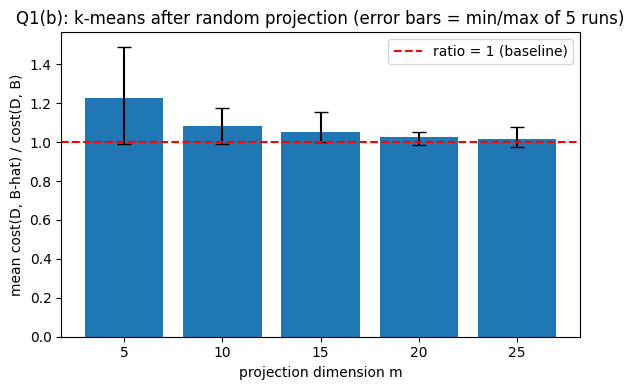


=== q1c_Bhat_vs_Bplus ===
   ratio_Bhat                     ratio_Bplus                      
         mean       min       max        mean        min        max
m                                                                  
5    1.227460  0.989865  1.489659   80.355849  79.090595  81.649469
10   1.082241  0.990799  1.174413   75.980500  72.574700  79.079926
15   1.050351  0.999487  1.154251   71.750097  69.419776  74.669252
20   1.026412  0.987058  1.052409   67.178194  63.896875  71.210471
25   1.015917  0.976318  1.075829   65.473657  59.552538  69.784089

=== q1d_time_summary ===
    time_projection  time_kmeans_E  time_total
m                                             
5          0.092155       4.786970    4.879125
10         0.100227       5.243272    5.343499
15         0.115209       6.052152    6.167361
20         0.120495       6.721257    6.841751
25         0.177935       7.212130    7.390065


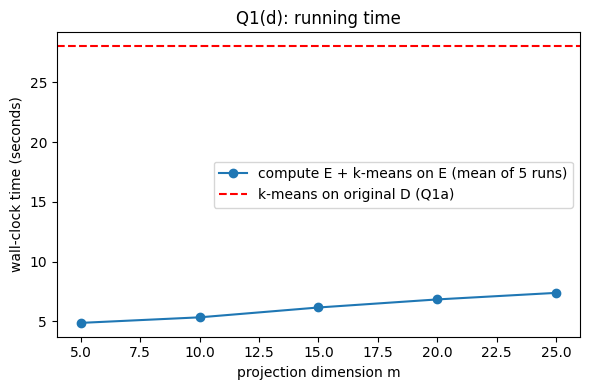

In [5]:
rng_q1b = np.random.default_rng(SEED + 1)
records = []

for m in M_LIST_Q1:
    for run in range(N_REPEATS):
        # ----- projection (timed) -----
        t0 = time.perf_counter()
        A = rng_q1b.normal(loc=0.0, scale=1.0 / np.sqrt(m), size=(m, d)).astype(np.float32)
        E = D @ A.T                                               # n x m
        time_projection = time.perf_counter() - t0

        # ----- k-means on E (timed) -----
        t0 = time.perf_counter()
        km_E = KMeans(n_clusters=K, n_init=N_INIT, random_state=SEED + run).fit(E)
        time_kmeans_E = time.perf_counter() - t0

        # ----- B-hat: average original rows in each cluster -----
        B_hat = cluster_means(D, km_E.labels_, K)
        cost_B_hat = cost_to_centres(D, B_hat)

        # ----- B+ : map the centres from R^m back to R^d with the pseudo-inverse -----
        A_pinv = np.linalg.pinv(A.astype(np.float64))             # d x m
        B_plus = km_E.cluster_centers_ @ A_pinv.T                 # (k x m) @ (m x d) = k x d
        cost_B_plus = cost_to_centres(D, B_plus)

        records.append({
            "m": m,
            "run": run,
            "cost_Bhat": cost_B_hat,
            "ratio_Bhat": cost_B_hat / cost_B,
            "cost_Bplus": cost_B_plus,
            "ratio_Bplus": cost_B_plus / cost_B,
            "time_projection": time_projection,
            "time_kmeans_E": time_kmeans_E,
            "time_total": time_projection + time_kmeans_E,
        })
        print(f"m={m:2d} run={run}  ratio_Bhat={cost_B_hat / cost_B:.4f}  "
              f"ratio_Bplus={cost_B_plus / cost_B:.4f}  time={time_projection + time_kmeans_E:.2f}s")

df_q1 = pd.DataFrame(records)
save_table(df_q1, "q1bcd_all_runs")

# ---------- Q1(b): mean / min / max ratio ----------
table_q1b = df_q1.groupby("m")["ratio_Bhat"].agg(["mean", "min", "max"])
save_table(table_q1b, "q1b_ratio_Bhat_summary")

means = table_q1b["mean"].values
lower = means - table_q1b["min"].values
upper = table_q1b["max"].values - means

plt.figure(figsize=(6, 4))
plt.bar(range(len(M_LIST_Q1)), means, yerr=[lower, upper], capsize=5)
plt.xticks(range(len(M_LIST_Q1)), M_LIST_Q1)
plt.axhline(1.0, color="red", linestyle="--", label="ratio = 1 (baseline)")
plt.xlabel("projection dimension m")
plt.ylabel("mean cost(D, B-hat) / cost(D, B)")
plt.title("Q1(b): k-means after random projection (error bars = min/max of 5 runs)")
plt.legend()
save_figure("q1b_ratio_bar")

# ---------- Q1(c): B-hat versus B+ ----------
table_q1c = df_q1.groupby("m")[["ratio_Bhat", "ratio_Bplus"]].agg(["mean", "min", "max"])
save_table(table_q1c, "q1c_Bhat_vs_Bplus")

# ---------- Q1(d): time ----------
table_q1d = df_q1.groupby("m")[["time_projection", "time_kmeans_E", "time_total"]].mean()
save_table(table_q1d, "q1d_time_summary")

plt.figure(figsize=(6, 4))
plt.plot(M_LIST_Q1, table_q1d["time_total"].values, marker="o", label="compute E + k-means on E (mean of 5 runs)")
plt.axhline(time_kmeans_orig, color="red", linestyle="--", label="k-means on original D (Q1a)")
plt.xlabel("projection dimension m")
plt.ylabel("wall-clock time (seconds)")
plt.title("Q1(d): running time")
plt.legend()
save_figure("q1d_time_plot")

## Q1(e) – how well are distances preserved?  (9 marks)
(i) 10,000 random pairs (i, l) with D_i != D_l (same pairs for every m), ONE draw of A per m:
    ratio = ||E_i - E_l||^2 / ||D_i - D_l||^2
(ii) 20 independent draws of A per m, clusters C_D from Q1(a):
    ratio = cost_E(C_D) / cost_D(C_D)

Pairs: 10000 | smallest original squared distance: 5.452589739572014e-13
cost_D(C_D) = 53498.03538292972
m= 5: pair ratio std=0.5833 | cost ratio std=0.1911
m=10: pair ratio std=0.4579 | cost ratio std=0.1135
m=15: pair ratio std=0.2719 | cost ratio std=0.0730
m=20: pair ratio std=0.1450 | cost ratio std=0.0487
m=25: pair ratio std=0.2206 | cost ratio std=0.0697

=== q1e_spread_summary ===
    pair_mean  pair_std  pair_IQR  cost_mean  cost_std  cost_IQR
m                                                               
5    0.972917  0.583309  0.630196   1.055844  0.191125  0.150912
10   1.344251  0.457875  0.411918   1.012222  0.113507  0.176973
15   0.755857  0.271918  0.410324   1.013365  0.072963  0.074047
20   0.919797  0.144950  0.125964   0.987458  0.048713  0.092221
25   0.979995  0.220594  0.173560   1.003993  0.069666  0.106959


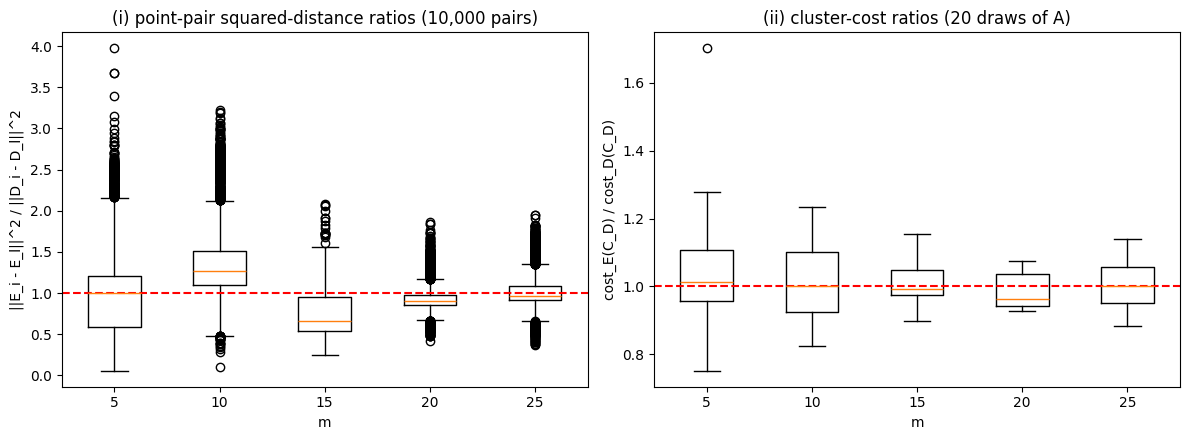

In [6]:
rng_q1e = np.random.default_rng(SEED + 2)

# ----- choose 10,000 pairs with D_i != D_l (KDD has many duplicate rows, so we must check) -----
pair_i = np.empty(0, dtype=np.int64)
pair_l = np.empty(0, dtype=np.int64)
while len(pair_i) < N_PAIRS:
    i = rng_q1e.integers(0, n, size=N_PAIRS)
    l = rng_q1e.integers(0, n, size=N_PAIRS)
    diff = D[i].astype(np.float64) - D[l].astype(np.float64)
    sq = (diff ** 2).sum(axis=1)
    keep = (i != l) & (sq > 0)                        # different rows AND different values
    pair_i = np.concatenate([pair_i, i[keep]])
    pair_l = np.concatenate([pair_l, l[keep]])
pair_i = pair_i[:N_PAIRS]
pair_l = pair_l[:N_PAIRS]

orig_diff = D[pair_i].astype(np.float64) - D[pair_l].astype(np.float64)
orig_sq_dist = (orig_diff ** 2).sum(axis=1)
print("Pairs:", len(pair_i), "| smallest original squared distance:", orig_sq_dist.min())

# cost_D(C_D): cost of the original clustering measured in the original space
cost_D_CD = partition_cost(D, labels_D, K)
print("cost_D(C_D) =", cost_D_CD)

pair_ratios = {}      # m -> array of 10,000 ratios
cost_ratios = {}      # m -> array of 20 ratios

for m in M_LIST_Q1:
    # ----- (i) one A, pair ratios -----
    A = rng_q1e.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))
    Ei = D[pair_i].astype(np.float64) @ A.T
    El = D[pair_l].astype(np.float64) @ A.T
    proj_sq_dist = ((Ei - El) ** 2).sum(axis=1)
    pair_ratios[m] = proj_sq_dist / orig_sq_dist

    # ----- (ii) 20 independent A, cluster-cost ratios -----
    ratios = []
    for draw in range(N_DRAWS_Q1E):
        A = rng_q1e.normal(0.0, 1.0 / np.sqrt(m), size=(m, d)).astype(np.float32)
        E = D @ A.T
        ratios.append(partition_cost(E, labels_D, K) / cost_D_CD)
    cost_ratios[m] = np.array(ratios)
    print(f"m={m:2d}: pair ratio std={pair_ratios[m].std():.4f} | cost ratio std={cost_ratios[m].std():.4f}")

# ----- spread table -----
spread_rows = []
for m in M_LIST_Q1:
    pr, cr = pair_ratios[m], cost_ratios[m]
    spread_rows.append({
        "m": m,
        "pair_mean": pr.mean(), "pair_std": pr.std(),
        "pair_IQR": np.percentile(pr, 75) - np.percentile(pr, 25),
        "cost_mean": cr.mean(), "cost_std": cr.std(),
        "cost_IQR": np.percentile(cr, 75) - np.percentile(cr, 25),
    })
save_table(pd.DataFrame(spread_rows).set_index("m"), "q1e_spread_summary")

# ----- one figure with both sets of box plots -----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].boxplot([pair_ratios[m] for m in M_LIST_Q1])
axes[0].set_xticks(range(1, len(M_LIST_Q1) + 1))
axes[0].set_xticklabels(M_LIST_Q1)
axes[0].axhline(1.0, color="red", linestyle="--")
axes[0].set_title("(i) point-pair squared-distance ratios (10,000 pairs)")
axes[0].set_xlabel("m")
axes[0].set_ylabel("||E_i - E_l||^2 / ||D_i - D_l||^2")

axes[1].boxplot([cost_ratios[m] for m in M_LIST_Q1])
axes[1].set_xticks(range(1, len(M_LIST_Q1) + 1))
axes[1].set_xticklabels(M_LIST_Q1)
axes[1].axhline(1.0, color="red", linestyle="--")
axes[1].set_title("(ii) cluster-cost ratios (20 draws of A)")
axes[1].set_xlabel("m")
axes[1].set_ylabel("cost_E(C_D) / cost_D(C_D)")
save_figure("q1e_boxplots")

## Q2 – set-up: label vector y and a float64 copy of D
Least squares is numerically more reliable in float64, so Q2 uses `D64`.
`y = 1` for an attack, `0` for a normal connection.

In [7]:
y = (target_labels != b"normal.").to_numpy(dtype=float)
D64 = D.astype(np.float64)

print("D64 shape:", D64.shape, "| y shape:", y.shape)
print("Fraction of attack connections:", y.mean())
assert len(y) == n

# rank(D) is needed to discuss Q2(b): the one-hot columns add up to 1, so rank(D) < d
rank_D = int(np.linalg.matrix_rank(D64))
print("d =", d, "| rank(D) =", rank_D)
scalars["rank_D"] = rank_D

D64 shape: (494021, 116) | y shape: (494021,)
Fraction of attack connections: 0.8030893423558918
d = 116 | rank(D) = 113


## Q2 – helper functions (CountSketch)
For every row i: bucket h(i) uniform in {0..m-1}, sign sigma(i) uniform in {-1,+1}.
Row i of D is added (times sigma(i)) to row h(i) of SD. S is NEVER stored as a dense matrix.

In [8]:
def draw_countsketch(n_rows, m, rng):
    """Draw the random buckets h and signs sigma that define S."""
    h = rng.integers(0, m, size=n_rows)
    sigma = rng.choice(np.array([-1.0, 1.0]), size=n_rows)
    return h, sigma


def apply_countsketch(M, h, sigma, m):
    """Return S @ M using numpy.add.at (M can be a matrix or a vector)."""
    if M.ndim == 1:
        SM = np.zeros(m)
        np.add.at(SM, h, sigma * M)
    else:
        SM = np.zeros((m, M.shape[1]))
        np.add.at(SM, h, sigma[:, None] * M)
    return SM


def loss(Dmat, yvec, a):
    """Loss(D, y, a) = ||D a - y||_2^2"""
    r = Dmat @ a - yvec
    return float(r @ r)

## Q2(a) – ordinary regression on the full data  (3 marks)
Time is averaged over 5 repeats of the same solve (the first call can be slower because of warm-up).

In [9]:
times = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    b = np.linalg.lstsq(D64, y, rcond=None)[0]
    times.append(time.perf_counter() - t0)
time_lstsq_orig = float(np.mean(times))

loss_b = loss(D64, y, b)
print("Loss(D, y, b)                 :", loss_b)
print("Time to compute b (mean, sec) :", time_lstsq_orig, "| individual:", np.round(times, 4))
print("First 10 coefficients of b    :", np.round(b[:10], 4))

scalars["q2a_loss_b"] = loss_b
scalars["q2a_time_sec"] = time_lstsq_orig
pd.DataFrame({"coefficient": b}).to_csv(f"{OUT_DIR}/q2a_coefficients_b.csv")

Loss(D, y, b)                 : 2949.7888148574198
Time to compute b (mean, sec) : 6.7430617386 | individual: [6.377  7.2715 6.4283 7.3413 6.2973]
First 10 coefficients of b    : [ 2.16000e-02  8.80000e-01  5.90700e-01  9.75000e-02  9.56500e-01
 -5.98100e-01  2.06610e+00  8.52200e-01  3.04300e-01  9.62424e+01]


## Q2(b) and Q2(c) – CountSketch regression  (12 + 4 marks)
For each m and each of 5 fresh sketches we record
* Loss(D,y,a~), the ratio to Loss(D,y,b), and the sketched loss ||S D a~ - S y||^2   (Q2b)
* time to draw S, time to form SD and Sy, time to solve, and their total              (Q2c)

m=  50 run=0  ratio=2.6810  sketched_loss=0.00  time=1.858s
m=  50 run=1  ratio=3.7327  sketched_loss=0.00  time=2.495s
m=  50 run=2  ratio=3.1051  sketched_loss=0.00  time=2.262s
m=  50 run=3  ratio=2.7525  sketched_loss=0.00  time=1.842s
m=  50 run=4  ratio=4.1247  sketched_loss=0.00  time=1.851s
m= 100 run=0  ratio=15.4196  sketched_loss=0.00  time=1.873s
m= 100 run=1  ratio=50.0341  sketched_loss=0.00  time=1.886s
m= 100 run=2  ratio=9.3386  sketched_loss=0.00  time=2.214s
m= 100 run=3  ratio=26.1486  sketched_loss=0.00  time=2.589s
m= 100 run=4  ratio=13.8947  sketched_loss=0.00  time=1.830s
m= 200 run=0  ratio=3.1196  sketched_loss=1627.58  time=1.848s
m= 200 run=1  ratio=2.3293  sketched_loss=1355.74  time=1.835s
m= 200 run=2  ratio=2.4098  sketched_loss=1389.90  time=1.884s
m= 200 run=3  ratio=2.0652  sketched_loss=1024.53  time=1.870s
m= 200 run=4  ratio=2.2936  sketched_loss=1392.39  time=2.968s
m= 500 run=0  ratio=1.3175  sketched_loss=2227.25  time=1.983s
m= 500 run=1  rati

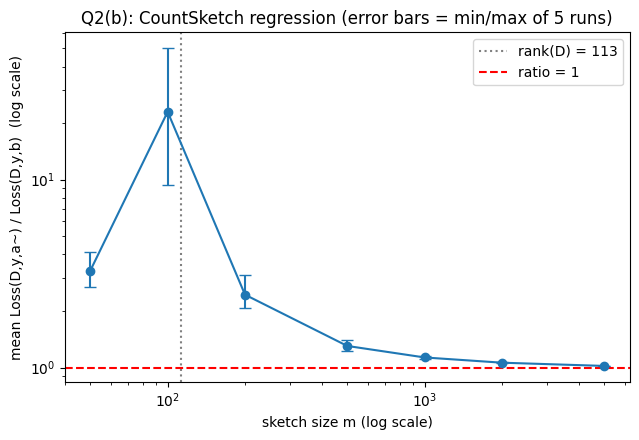

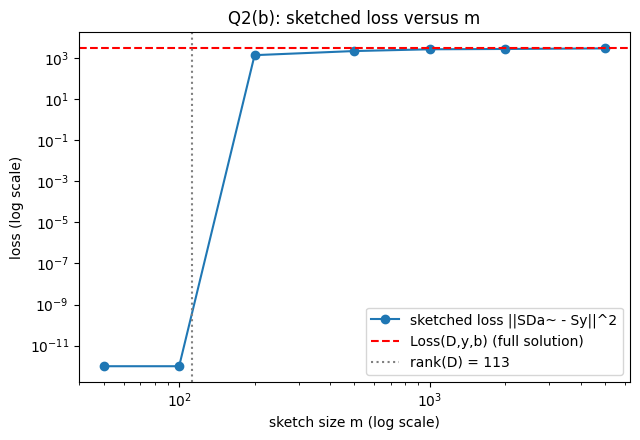


=== q2c_time_summary ===
        t_draw    t_form   t_solve   t_total  t_full_regression_Q2a  speed_up_vs_full
m                                                                                    
50    0.009592  2.051064  0.000943  2.061600               6.743062          3.270791
100   0.009487  2.038550  0.030493  2.078529               6.743062          3.244151
200   0.007760  2.038352  0.034673  2.080786               6.743062          3.240633
500   0.008647  1.882386  0.006962  1.897995               6.743062          3.552729
1000  0.009483  2.114812  0.065284  2.189580               6.743062          3.079614
2000  0.008641  2.180831  0.033474  2.222946               6.743062          3.033390
5000  0.007728  2.289050  0.050295  2.347073               6.743062          2.872966


In [10]:
rng_q2b = np.random.default_rng(SEED + 3)
records = []

for m in M_LIST_Q2:
    for run in range(N_REPEATS):
        # draw S (i.e. buckets and signs)
        t0 = time.perf_counter()
        h, sigma = draw_countsketch(n, m, rng_q2b)
        t_draw = time.perf_counter() - t0

        # form SD and Sy
        t0 = time.perf_counter()
        SD = apply_countsketch(D64, h, sigma, m)
        Sy = apply_countsketch(y, h, sigma, m)
        t_form = time.perf_counter() - t0

        # solve the sketched regression
        t0 = time.perf_counter()
        a_tilde = np.linalg.lstsq(SD, Sy, rcond=None)[0]
        t_solve = time.perf_counter() - t0

        loss_a = loss(D64, y, a_tilde)                 # loss on the ORIGINAL data
        sketched_loss = loss(SD, Sy, a_tilde)          # ||S D a~ - S y||^2

        records.append({
            "m": m, "run": run,
            "loss_a_tilde": loss_a,
            "ratio": loss_a / loss_b,
            "sketched_loss": sketched_loss,
            "t_draw": t_draw, "t_form": t_form, "t_solve": t_solve,
            "t_total": t_draw + t_form + t_solve,
        })
        print(f"m={m:4d} run={run}  ratio={loss_a / loss_b:.4f}  "
              f"sketched_loss={sketched_loss:.2f}  time={t_draw + t_form + t_solve:.3f}s")

df_q2 = pd.DataFrame(records)
save_table(df_q2, "q2bc_all_runs")

# ---------- Q2(b) ----------
table_q2b = df_q2.groupby("m").agg(
    loss_mean=("loss_a_tilde", "mean"),
    ratio_mean=("ratio", "mean"),
    ratio_min=("ratio", "min"),
    ratio_max=("ratio", "max"),
    sketched_loss_mean=("sketched_loss", "mean"),
)
save_table(table_q2b, "q2b_summary")

ratio_mean = table_q2b["ratio_mean"].values
err_low = ratio_mean - table_q2b["ratio_min"].values
err_high = table_q2b["ratio_max"].values - ratio_mean

plt.figure(figsize=(6.5, 4.5))
plt.errorbar(M_LIST_Q2, ratio_mean, yerr=[err_low, err_high], marker="o", capsize=4)
plt.xscale("log")
plt.yscale("log")
plt.axvline(rank_D, color="gray", linestyle=":", label=f"rank(D) = {rank_D}")
plt.axhline(1.0, color="red", linestyle="--", label="ratio = 1")
plt.xlabel("sketch size m (log scale)")
plt.ylabel("mean Loss(D,y,a~) / Loss(D,y,b)  (log scale)")
plt.title("Q2(b): CountSketch regression (error bars = min/max of 5 runs)")
plt.legend()
save_figure("q2b_ratio_loglog")

# extra figure to discuss the sketched loss below / above rank(D)
sk_mean = table_q2b["sketched_loss_mean"].values
plt.figure(figsize=(6.5, 4.5))
plt.plot(M_LIST_Q2, np.maximum(sk_mean, 1e-12), marker="o", label="sketched loss ||SDa~ - Sy||^2")
plt.axhline(loss_b, color="red", linestyle="--", label="Loss(D,y,b) (full solution)")
plt.axvline(rank_D, color="gray", linestyle=":", label=f"rank(D) = {rank_D}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("sketch size m (log scale)")
plt.ylabel("loss (log scale)")
plt.title("Q2(b): sketched loss versus m")
plt.legend()
save_figure("q2b_sketched_loss")

# ---------- Q2(c) ----------
table_q2c = df_q2.groupby("m")[["t_draw", "t_form", "t_solve", "t_total"]].mean()
table_q2c["t_full_regression_Q2a"] = time_lstsq_orig
table_q2c["speed_up_vs_full"] = time_lstsq_orig / table_q2c["t_total"]
save_table(table_q2c, "q2c_time_summary")

## Q2(d) – is the residual preserved?  (5 marks)
v = D b - y.  For m in {50, 500, 5000}: 100 independent CountSketches, ratio = ||S v||^2 / ||v||^2.

||v||^2 = 2949.7888148574198 (should equal Loss(D,y,b) = 2949.7888148574198 )

=== q2d_residual_ratio_summary ===
          mean       std
m                       
50    0.985196  0.193603
500   1.008919  0.065663
5000  0.996095  0.019216


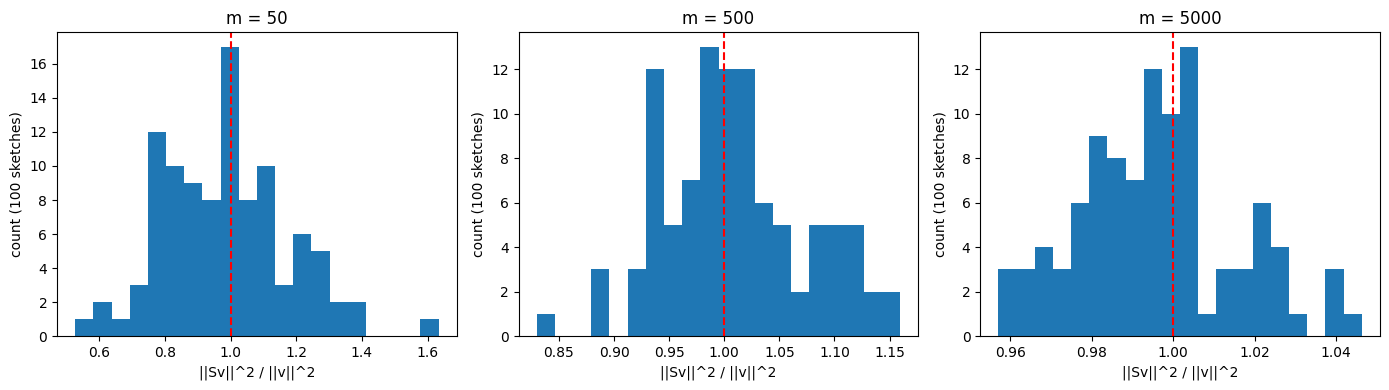

In [11]:
rng_q2d = np.random.default_rng(SEED + 4)
v = D64 @ b - y
v_sq = float(v @ v)
print("||v||^2 =", v_sq, "(should equal Loss(D,y,b) =", loss_b, ")")

resid_ratios = {}
rows = []
for m in M_LIST_Q2D:
    ratios = []
    for draw in range(N_DRAWS_Q2D):
        h, sigma = draw_countsketch(n, m, rng_q2d)
        Sv = apply_countsketch(v, h, sigma, m)
        ratios.append(float(Sv @ Sv) / v_sq)
    resid_ratios[m] = np.array(ratios)
    rows.append({"m": m, "mean": resid_ratios[m].mean(), "std": resid_ratios[m].std(ddof=1)})
save_table(pd.DataFrame(rows).set_index("m"), "q2d_residual_ratio_summary")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, M_LIST_Q2D):
    ax.hist(resid_ratios[m], bins=20)
    ax.axvline(1.0, color="red", linestyle="--")
    ax.set_title(f"m = {m}")
    ax.set_xlabel("||Sv||^2 / ||v||^2")
    ax.set_ylabel("count (100 sketches)")
save_figure("q2d_histograms")

## Q2(e) – CountSketch versus dense Gaussian sketch  (6 marks)
One fixed random subset of 50,000 rows (fixed seed), used for both methods and all 5 repetitions.
m = 500. Gaussian entries are N(0, 1/m), i.e. standard deviation 1/sqrt(m). A fresh sketch every repetition.

In [12]:
rng_subset = np.random.default_rng(SEED)                     # fixed seed for the subset
subset_idx = rng_subset.choice(n, size=N_SUBSET, replace=False)
D_sub = D64[subset_idx]
y_sub = y[subset_idx]

b_sub = np.linalg.lstsq(D_sub, y_sub, rcond=None)[0]
loss_b_sub = loss(D_sub, y_sub, b_sub)
print("Loss(D', y', b') =", loss_b_sub)

rng_q2e = np.random.default_rng(SEED + 5)
records = []
for run in range(N_REPEATS):
    # ---------------- (i) CountSketch ----------------
    t0 = time.perf_counter()
    h, sigma = draw_countsketch(N_SUBSET, M_Q2E, rng_q2e)
    t_draw = time.perf_counter() - t0

    t0 = time.perf_counter()
    SD = apply_countsketch(D_sub, h, sigma, M_Q2E)
    Sy = apply_countsketch(y_sub, h, sigma, M_Q2E)
    t_form = time.perf_counter() - t0

    t0 = time.perf_counter()
    a_tilde = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    t_solve = time.perf_counter() - t0

    records.append({
        "method": "CountSketch", "run": run,
        "t_draw": t_draw, "t_form": t_form, "t_solve": t_solve,
        "t_sketch": t_draw + t_form,                       # draw S + form SD' and Sy'
        "t_total": t_draw + t_form + t_solve,
        "loss_ratio": loss(D_sub, y_sub, a_tilde) / loss_b_sub,
    })

    # ---------------- (ii) dense Gaussian sketch ----------------
    t0 = time.perf_counter()
    S = rng_q2e.normal(0.0, 1.0 / np.sqrt(M_Q2E), size=(M_Q2E, N_SUBSET))
    t_draw = time.perf_counter() - t0

    t0 = time.perf_counter()
    SD = S @ D_sub
    Sy = S @ y_sub
    t_form = time.perf_counter() - t0

    t0 = time.perf_counter()
    a_tilde = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    t_solve = time.perf_counter() - t0

    records.append({
        "method": "Gaussian", "run": run,
        "t_draw": t_draw, "t_form": t_form, "t_solve": t_solve,
        "t_sketch": t_draw + t_form,
        "t_total": t_draw + t_form + t_solve,
        "loss_ratio": loss(D_sub, y_sub, a_tilde) / loss_b_sub,
    })
    del S

df_q2e = pd.DataFrame(records)
save_table(df_q2e, "q2e_all_runs")

table_q2e = df_q2e.groupby("method")[["t_draw", "t_form", "t_solve", "t_sketch", "t_total", "loss_ratio"]].mean().T
save_table(table_q2e, "q2e_summary")

Loss(D', y', b') = 275.1544337525746

=== q2e_all_runs ===
        method  run    t_draw    t_form   t_solve  t_sketch   t_total  loss_ratio
0  CountSketch    0  0.000920  0.253174  0.013923  0.254094  0.268017    1.257410
1     Gaussian    0  0.706570  0.356065  0.079643  1.062635  1.142278    1.262074
2  CountSketch    1  0.001020  0.245138  0.010700  0.246158  0.256858    1.278897
3     Gaussian    1  0.642489  0.325188  0.015436  0.967677  0.983113    1.333867
4  CountSketch    2  0.003548  0.273025  0.046112  0.276572  0.322685    1.339981
5     Gaussian    2  0.637744  0.232552  0.005577  0.870296  0.875873    1.230423
6  CountSketch    3  0.000939  0.178523  0.005323  0.179461  0.184784    1.303883
7     Gaussian    3  0.489690  0.196710  0.005572  0.686399  0.691971    1.221799
8  CountSketch    4  0.000951  0.188249  0.005282  0.189200  0.194481    1.256531
9     Gaussian    4  0.491757  0.192865  0.005759  0.684623  0.690382    1.254837

=== q2e_summary ===
method      CountS

## Save everything and zip it

In [13]:
with open(f"{OUT_DIR}/scalars.json", "w") as f:
    json.dump(scalars, f, indent=2)
print(json.dumps(scalars, indent=2))

shutil.make_archive("assignment_results", "zip", OUT_DIR)
print("\nCreated assignment_results.zip with all tables (CSV), figures (PNG) and scalars.json")
# In Google Colab you can download it with:
# from google.colab import files; files.download("assignment_results.zip")

{
  "n": 494021,
  "d": 116,
  "quick_test": false,
  "q1a_cost_D_B": 53500.906744922744,
  "q1a_time_sec": 28.021618882999974,
  "rank_D": 113,
  "q2a_loss_b": 2949.7888148574198,
  "q2a_time_sec": 6.7430617386
}

Created assignment_results.zip with all tables (CSV), figures (PNG) and scalars.json
